In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [5]:
df = pd.read_csv('House_Rent_Dataset.csv')

In [6]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   str    
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   str    
 5   Area Type          4739 non-null   str    
 6   Area Locality      4746 non-null   str    
 7   City               4746 non-null   str    
 8   Furnishing Status  4746 non-null   str    
 9   Tenant Preferred   4746 non-null   str    
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   str    
dtypes: float64(3), int64(1), str(8)
memory usage: 445.1 KB


In [8]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [9]:
df.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact'],
      dtype='str')

In [10]:
df.shape

(4746, 12)

In [11]:
df.isna().sum()

Posted On            0
BHK                  0
Rent                 5
Size                 8
Floor                0
Area Type            7
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             4
Point of Contact     0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

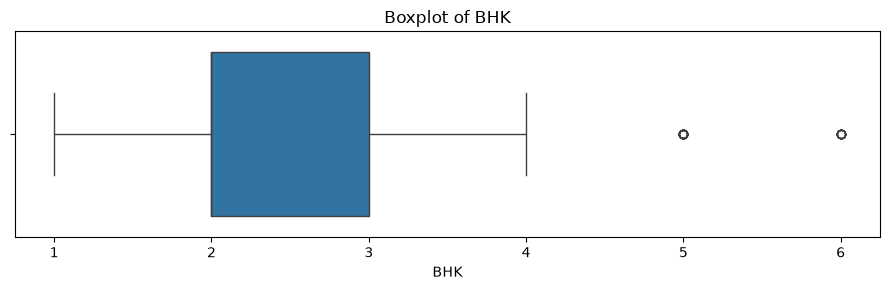

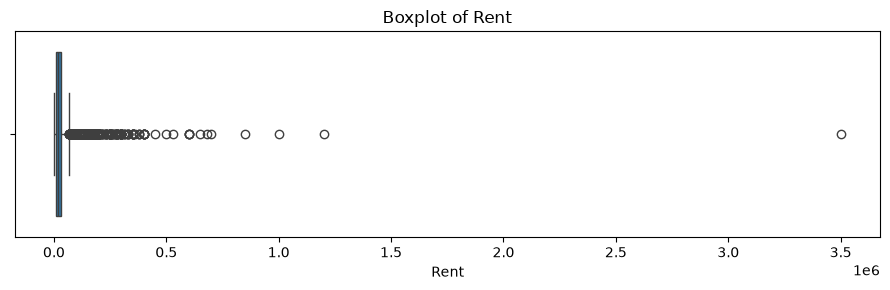

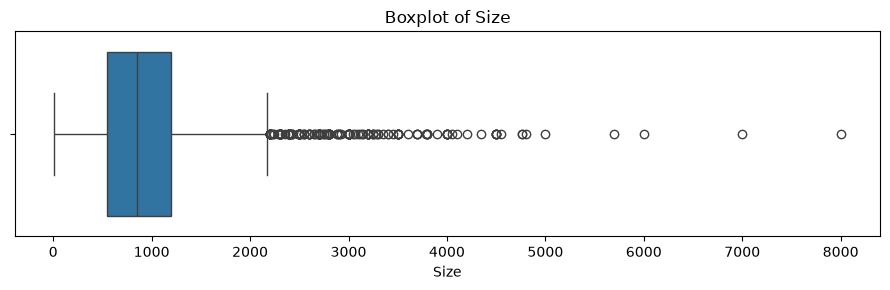

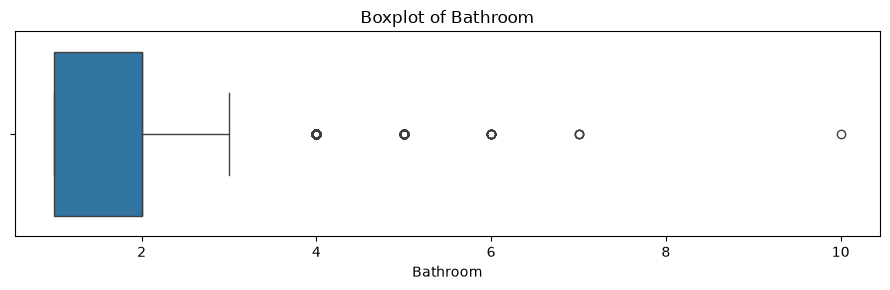

In [13]:
numeric_cols = ["BHK", "Rent", "Size", "Bathroom"]
for col in numeric_cols:
    plt.figure(figsize=(9, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

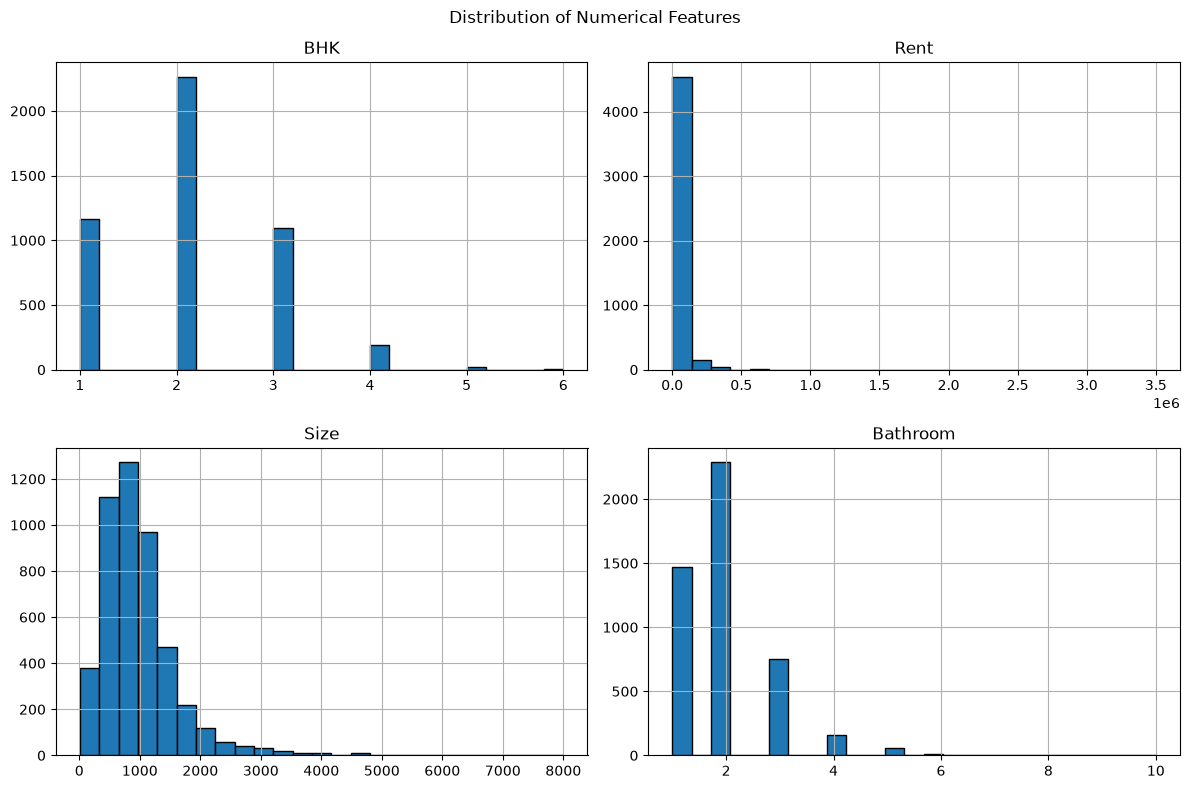

In [14]:
df[numeric_cols].hist(
    figsize=(12, 8),
    bins=25,
    edgecolor="black"
)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

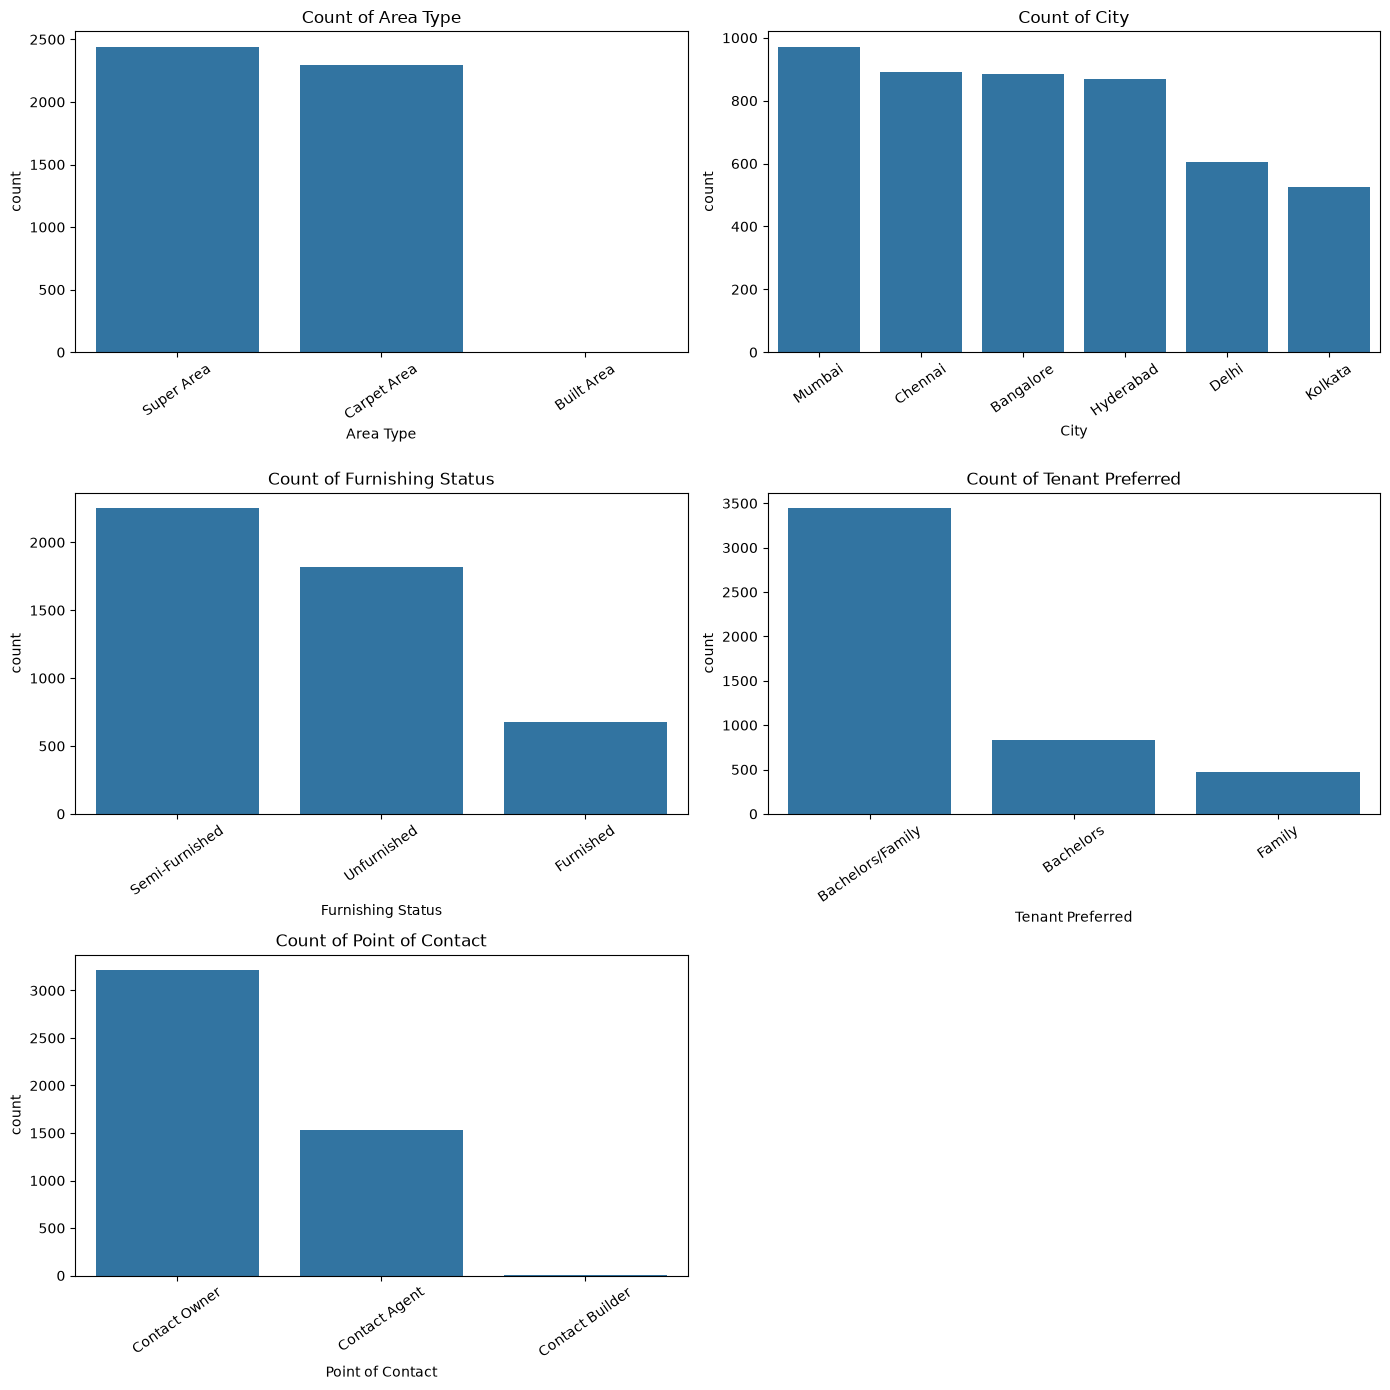

In [15]:
categorical_cols = [
    "Area Type",
    "City",
    "Furnishing Status",
    "Tenant Preferred",
    "Point of Contact"
]
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()
for col, ax in zip(categorical_cols, axes):
    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        ax=ax
    )
    ax.set_title(f"Count of {col}")
    ax.tick_params(axis="x", rotation=35)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

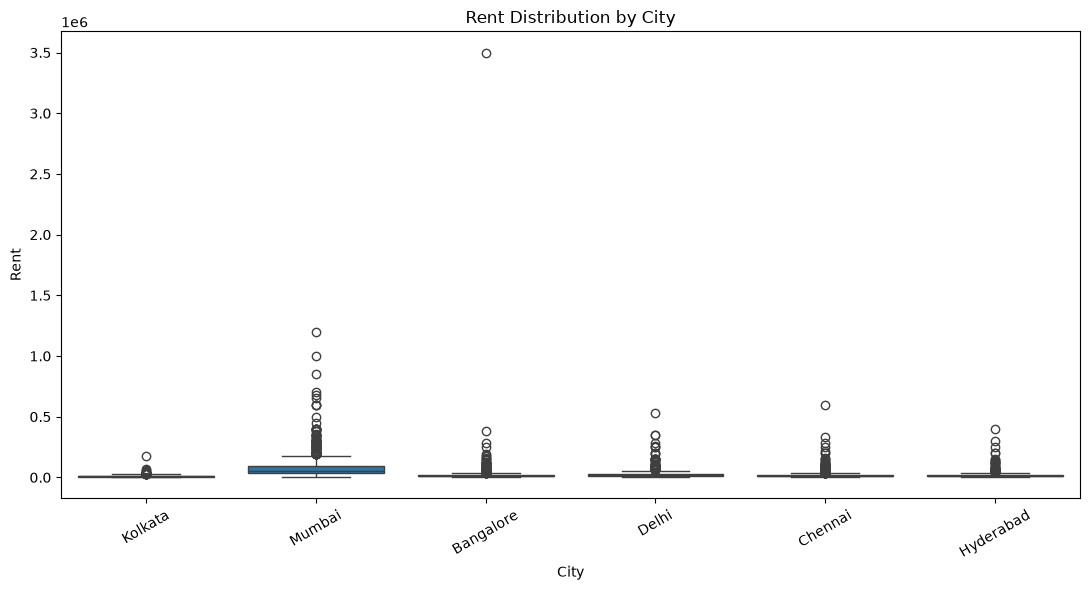

In [16]:
plt.figure(figsize=(11, 6))
sns.boxplot(data=df,x="City",y="Rent")
plt.title("Rent Distribution by City")
plt.xlabel("City")
plt.ylabel("Rent")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

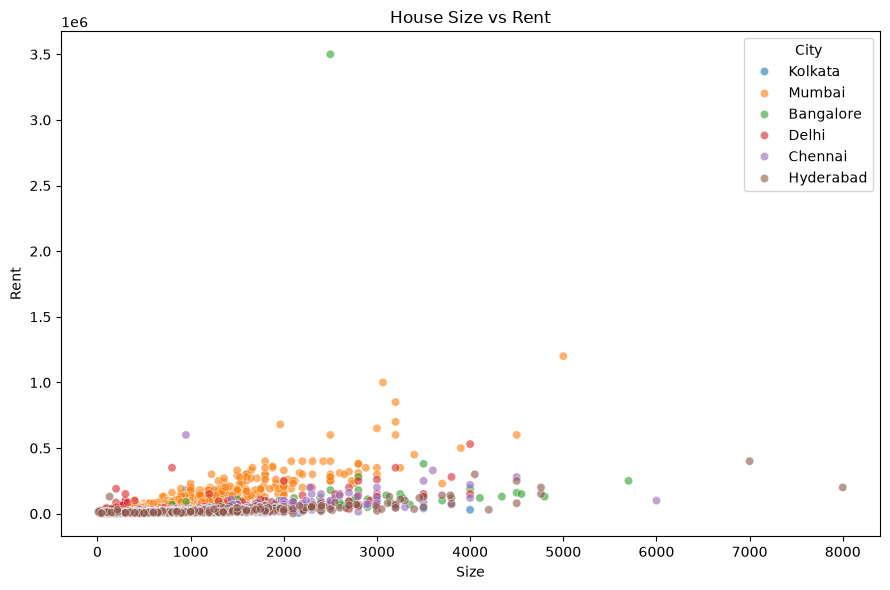

In [17]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df,x="Size",y="Rent",hue="City",alpha=0.6)
plt.title("House Size vs Rent")
plt.xlabel("Size")
plt.ylabel("Rent")
plt.tight_layout()
plt.show()

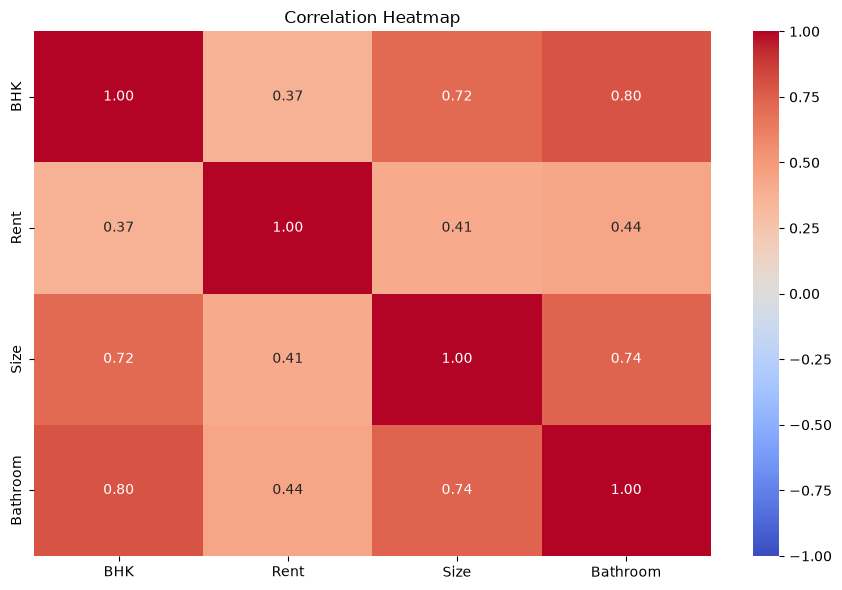

In [18]:
plt.figure(figsize=(9, 6))
corr = df[numeric_cols].corr()
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f",vmin=-1,vmax=1)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [19]:
print(
    df.nlargest(10, "Rent")[
        ["Rent", "City", "BHK", "Size", "Bathroom"]
    ]
)

           Rent       City  BHK    Size  Bathroom
1837  3500000.0  Bangalore    3  2500.0       3.0
1001  1200000.0     Mumbai    4  5000.0       4.0
827   1000000.0     Mumbai    4  3064.0       4.0
1329   850000.0     Mumbai    4  3200.0       4.0
1459   700000.0     Mumbai    4  3200.0       4.0
1484   680000.0     Mumbai    4  1962.0       5.0
1319   650000.0     Mumbai    5  3000.0       5.0
726    600000.0     Mumbai    4  2500.0       4.0
792    600000.0     Mumbai    5  3200.0       5.0
1384   600000.0     Mumbai    5  4500.0       5.0


In [20]:
print(
    df.nlargest(10, "Size")[
        ["Size", "Rent", "City", "BHK", "Bathroom"]
    ]
)

        Size       Rent       City  BHK  Bathroom
4185  8000.0   200000.0  Hyderabad    1      10.0
4457  7000.0   400000.0  Hyderabad    4       6.0
3622  6000.0   100000.0    Chennai    5       4.0
2048  5700.0   250000.0  Bangalore    4       4.0
1001  5000.0  1200000.0     Mumbai    4       4.0
1810  4800.0   130000.0  Bangalore    4       4.0
4241  4761.0   150000.0  Hyderabad    4       5.0
4543  4761.0   200000.0  Hyderabad    4       6.0
2236  4550.0   150000.0  Bangalore    4       5.0
1384  4500.0   600000.0     Mumbai    5       5.0


In [21]:
numeric_cols = ["Rent", "Size", "BHK", "Bathroom"]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]
    print(f"\n{col}")
    print("Outliers Count:", len(outliers))


Rent
Outliers Count: 520

Size
Outliers Count: 203

BHK
Outliers Count: 27

Bathroom
Outliers Count: 232


In [22]:
for col in ["Rent", "Size"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[col] = df[col].clip(
        lower=lower_bound,
        upper=upper_bound)

In [23]:

numeric_cols = ["Rent", "Size", "BHK", "Bathroom"]
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ][col]
    outliers_count = len(outliers)
    outliers_percentage = (outliers_count / df[col].notna().sum()) * 100
    print(f"\n{col}")
    print(f"Outliers Count: {outliers_count}")
    print(f"Outliers Percentage: {outliers_percentage:.2f}%")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")



Rent
Outliers Count: 0
Outliers Percentage: 0.00%
Lower Bound: -24500.00
Upper Bound: 67500.00

Size
Outliers Count: 0
Outliers Percentage: 0.00%
Lower Bound: -425.00
Upper Bound: 2175.00

BHK
Outliers Count: 27
Outliers Percentage: 0.57%
Lower Bound: 0.50
Upper Bound: 4.50

Bathroom
Outliers Count: 232
Outliers Percentage: 4.89%
Lower Bound: -0.50
Upper Bound: 3.50


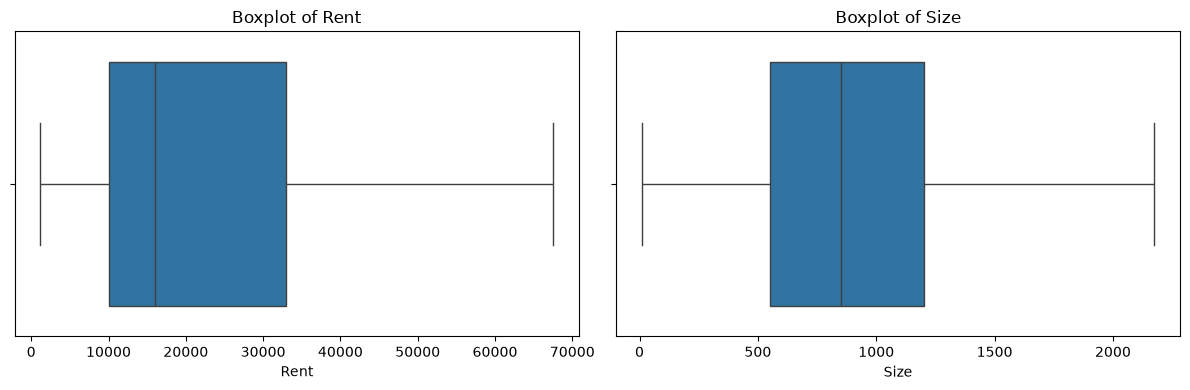

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["Rent"], ax=axes[0])
axes[0].set_title("Boxplot of Rent")
sns.boxplot(x=df["Size"], ax=axes[1])
axes[1].set_title("Boxplot of Size")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.impute import SimpleImputer
numeric_cols = ["Size", "Bathroom"]
num_imputer = SimpleImputer(strategy="median")
df[numeric_cols] = num_imputer.fit_transform(df[numeric_cols])
categorical_cols = ["Area Type"]
cat_imputer = SimpleImputer(strategy="most_frequent")
df[categorical_cols] = cat_imputer.fit_transform(df[categorical_cols])


In [38]:

# Feature Engineering

df = df.copy()

# Extract date features
if "Posted On" in df.columns:
    date = pd.to_datetime(df["Posted On"], errors="coerce")
    
    df["Posted_Year"] = date.dt.year
    df["Posted_Month"] = date.dt.month
    df["Posted_Day"] = date.dt.day
    
    df.drop(columns=["Posted On"], inplace=True)

# Separate Features and Target
df = df.dropna(subset=["Rent"])

X = df.drop(columns=["Rent"])
y = df["Rent"]

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:", numeric_cols)
print("Categorical Features:", categorical_cols)


Numerical Features: ['BHK', 'Size', 'Furnishing Status', 'Bathroom', 'Posted_Year', 'Posted_Month', 'Posted_Day']
Categorical Features: ['Floor', 'Area Type', 'Area Locality', 'City', 'Tenant Preferred', 'Point of Contact']


C:\Users\Dell\AppData\Local\Temp\ipykernel_19840\2445833284.py:24: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


In [39]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Numerical Pipeline
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

# Categorical Pipeline
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Column Transformer
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Apply Preprocessing
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (3792, 2388)
X_test: (949, 2388)


In [26]:
# عشان دا التارجت بتاعنا و احنا مش عايزين اي missing values فيه
df.dropna(subset=["Rent"], inplace=True)

In [27]:
print(df.isnull().sum())

Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64


In [28]:
from sklearn.model_selection import train_test_split
df = df.dropna(subset=["Rent"])
X = df.drop(columns=["Rent"])
y = df["Rent"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [29]:
df = df.copy()
date = pd.to_datetime(df["Posted On"], errors="coerce")
df["Posted_Year"] = date.dt.year
df["Posted_Month"] = date.dt.month
df["Posted_Day"] = date.dt.day
df.drop(columns=["Posted On"], inplace=True)
furnishing_map = {"Unfurnished": 0,"Semi-Furnished": 1,"Furnished": 2}
df["Furnishing Status"] = df["Furnishing Status"].map(furnishing_map)

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
categorical_cols = ["Area Type","City","Tenant Preferred","Point of Contact","Floor","Area Locality"]
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_transformer, numeric_cols),("cat", categorical_transformer, categorical_cols)])
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)
print("Train shape:", X_train_encoded.shape)
print("Test shape:", X_test_encoded.shape)

Train shape: (3792, 2384)
Test shape: (949, 2384)


In [31]:
df.head()

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Posted_Year,Posted_Month,Posted_Day
0,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,0,Bachelors/Family,2.0,Contact Owner,2022,5,18
1,2,20000.0,850.0,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,1,Bachelors/Family,1.0,Contact Owner,2022,5,13
2,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,1,Bachelors/Family,1.0,Contact Owner,2022,5,16
3,2,10000.0,850.0,1 out of 2,Super Area,Dumdum Park,Kolkata,0,Bachelors/Family,1.0,Contact Owner,2022,7,4
4,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,0,Bachelors,1.0,Contact Owner,2022,5,9


In [32]:
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()
lr_model.fit(X_train_encoded, y_train)
y_pred = lr_model.predict(X_test_encoded)

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 6613.969410607132
MSE: 90836607.55624953
RMSE: 9530.824075401326
R2 Score: 0.7729323605891044


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [35]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [36]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

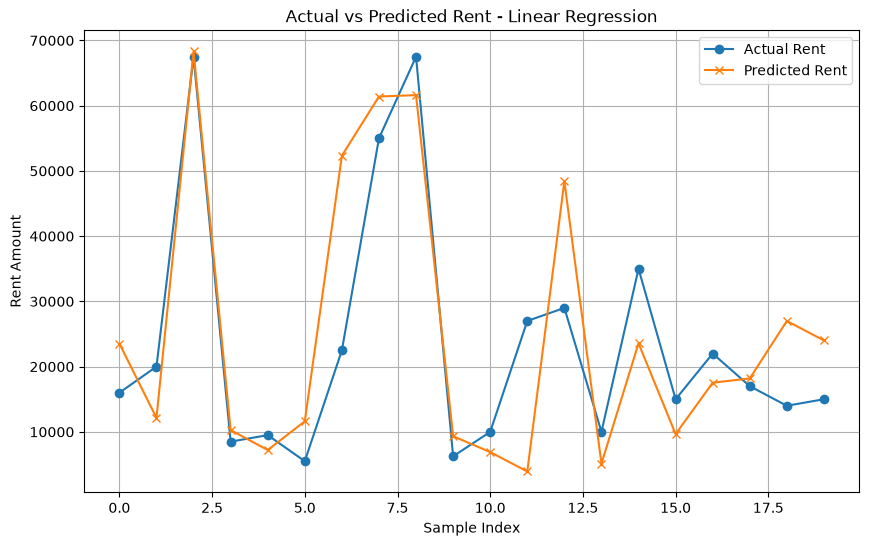

  7%|▋         | 1/15 [00:00<00:06,  2.13it/s]c:\Users\Dell\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.018735e+10, tolerance: 1.503e+08
  model = cd_fast.sparse_enet_coordinate_descent(


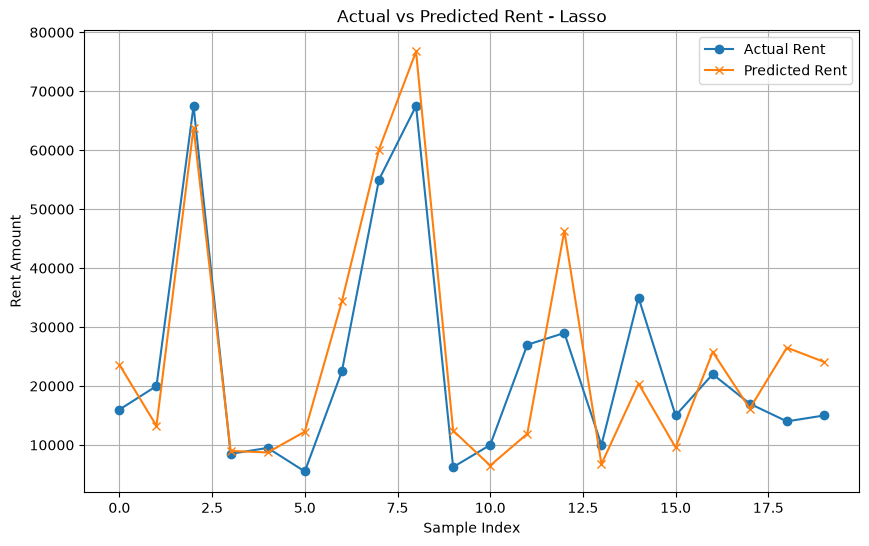

 13%|█▎        | 2/15 [00:02<00:16,  1.27s/it]

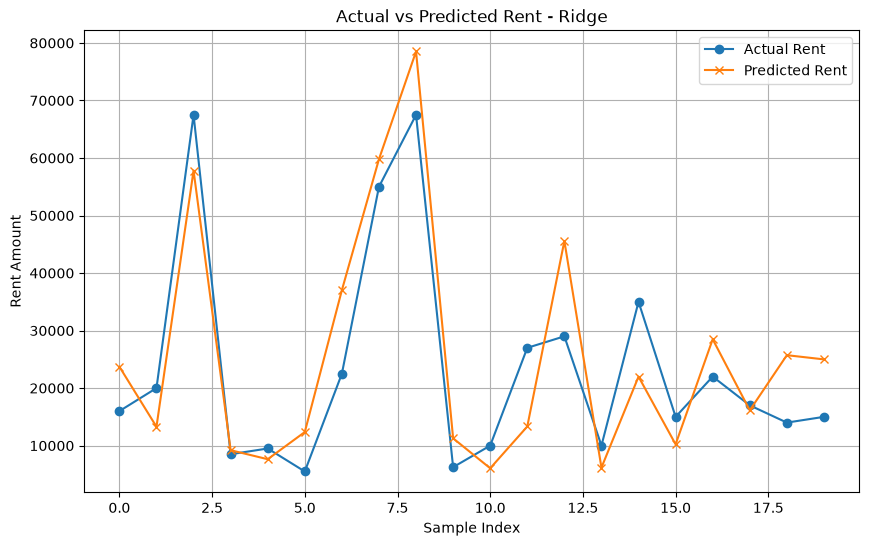

 20%|██        | 3/15 [00:02<00:09,  1.24it/s]

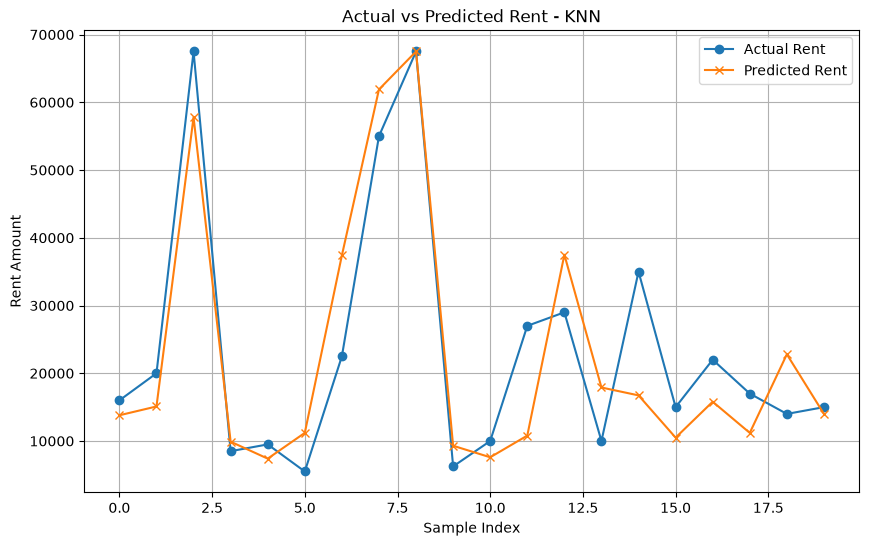

 27%|██▋       | 4/15 [00:03<00:08,  1.27it/s]

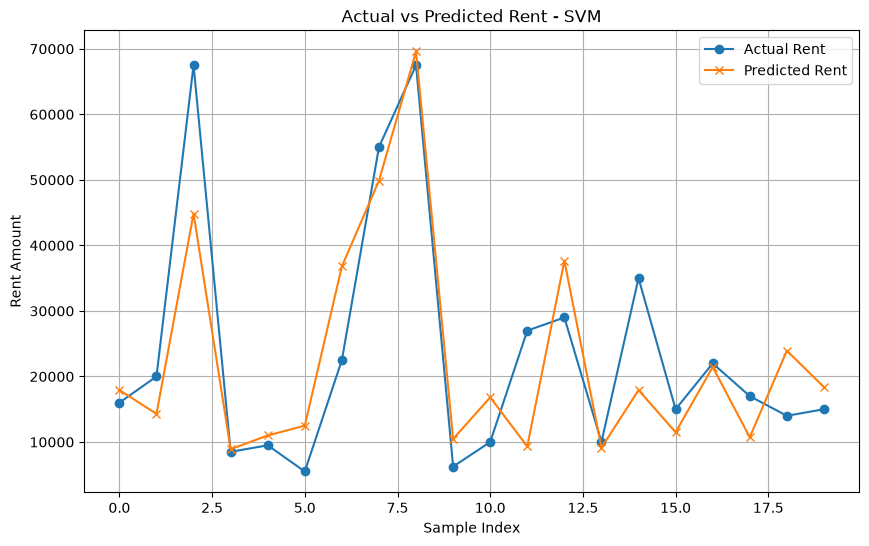

 33%|███▎      | 5/15 [00:05<00:13,  1.35s/it]

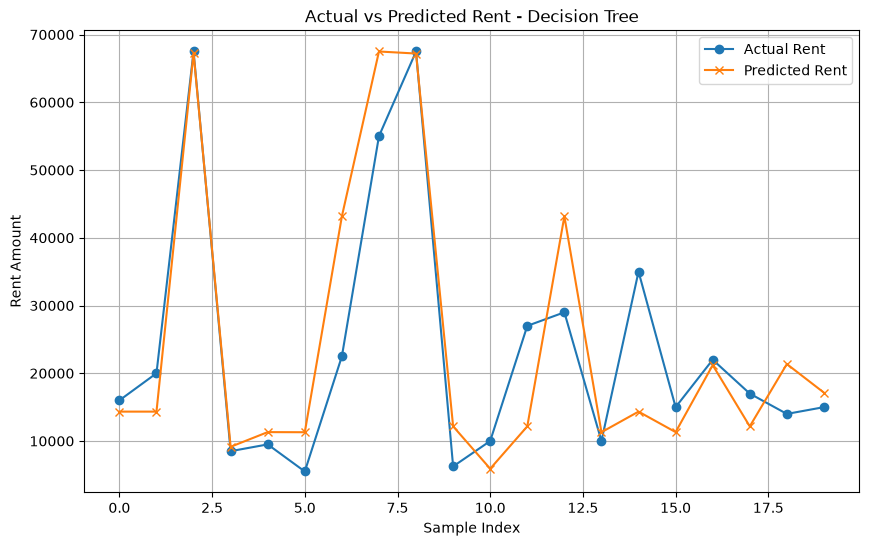

 40%|████      | 6/15 [00:05<00:08,  1.02it/s]

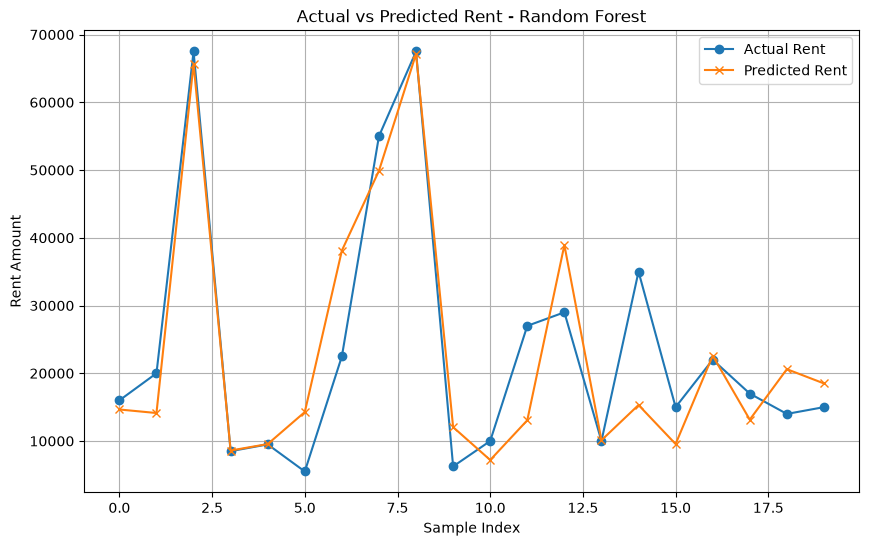

 47%|████▋     | 7/15 [00:08<00:12,  1.52s/it]

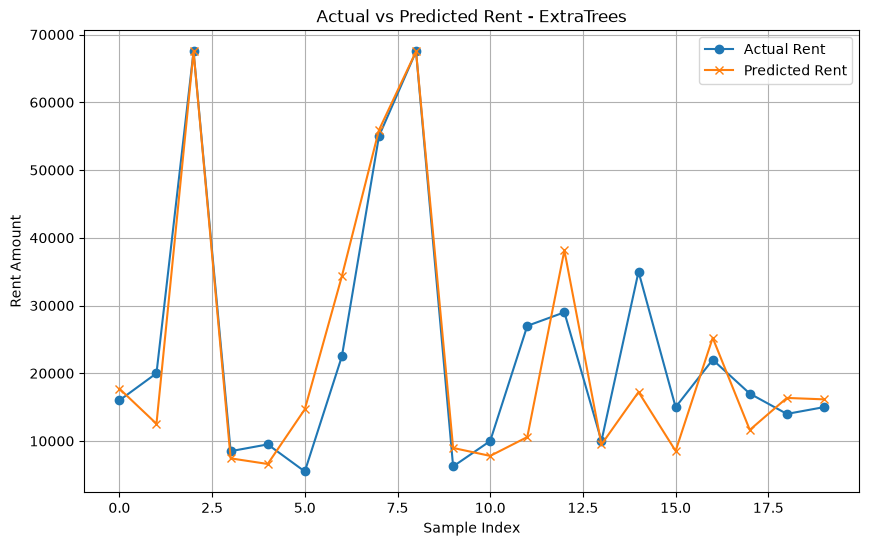

 53%|█████▎    | 8/15 [00:41<01:21, 11.59s/it]

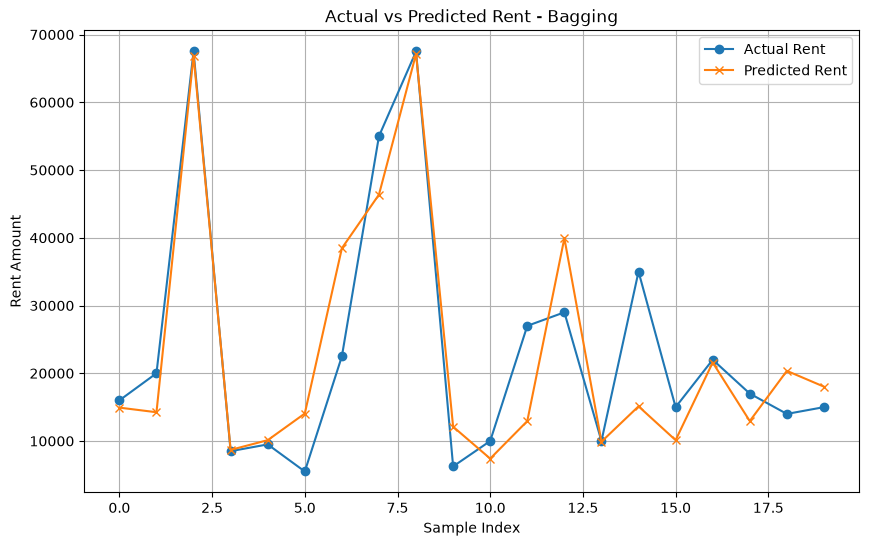

 60%|██████    | 9/15 [00:44<00:53,  8.87s/it]

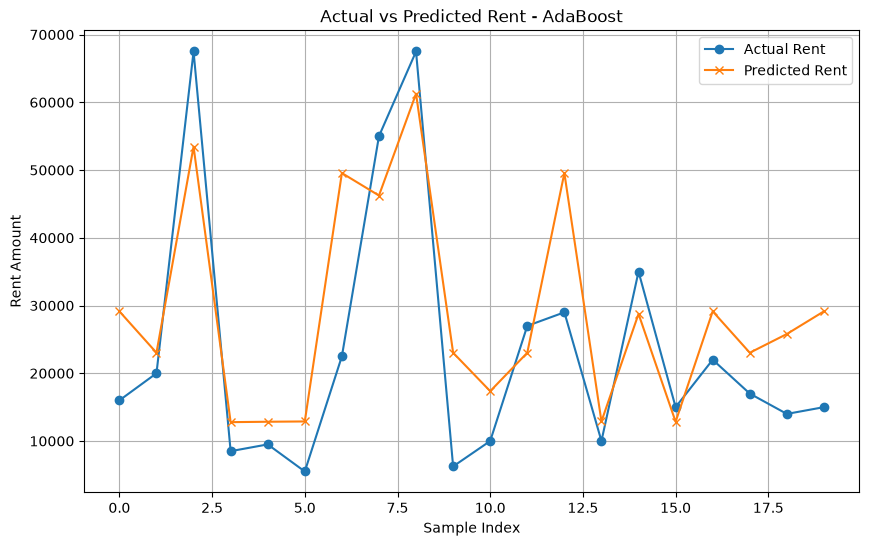

 67%|██████▋   | 10/15 [00:45<00:31,  6.27s/it]

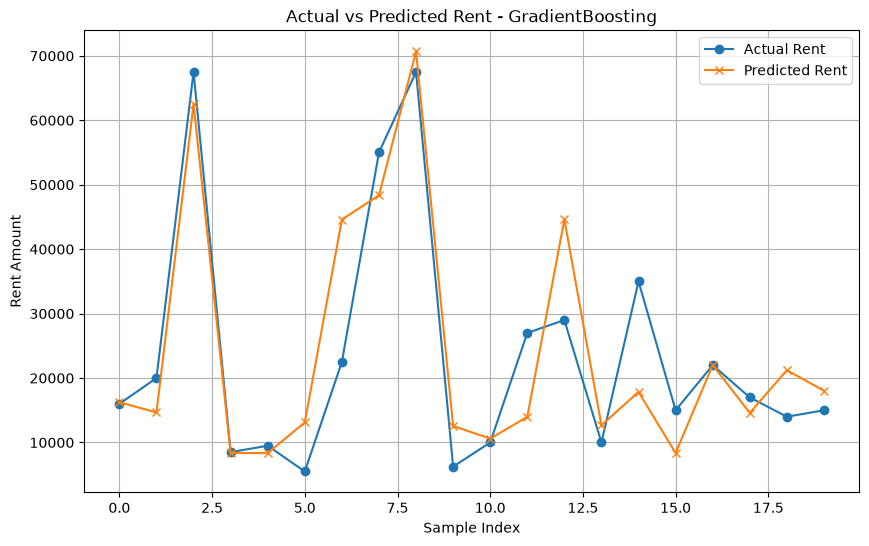

 73%|███████▎  | 11/15 [00:46<00:19,  4.83s/it]

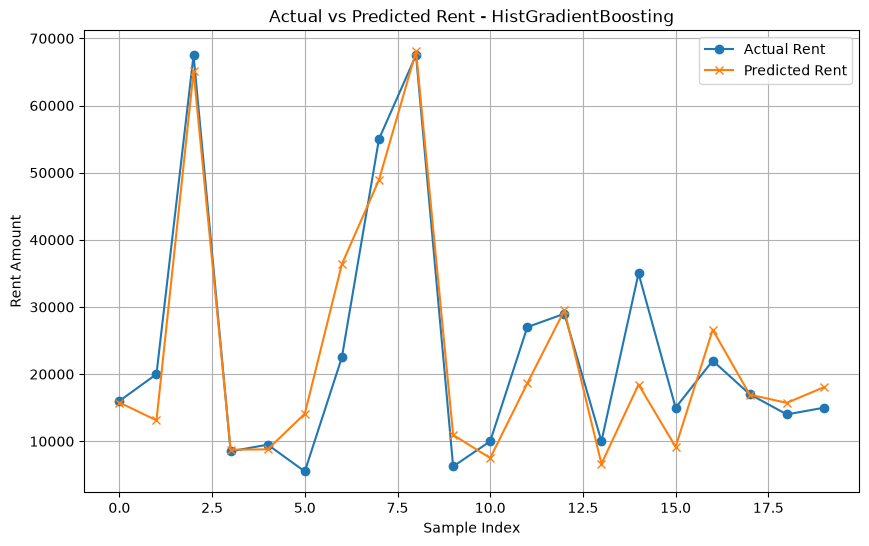

 80%|████████  | 12/15 [00:58<00:21,  7.04s/it]

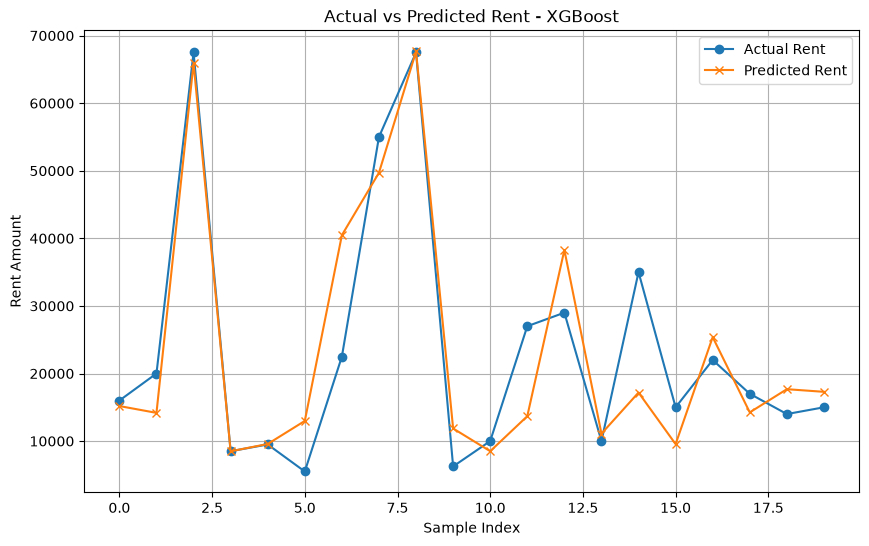

 87%|████████▋ | 13/15 [00:59<00:10,  5.11s/it]

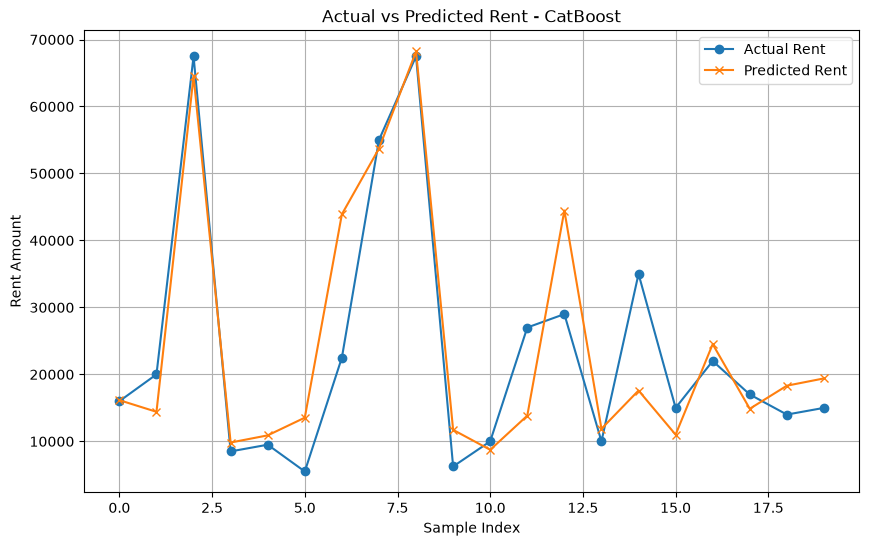

 93%|█████████▎| 14/15 [01:01<00:04,  4.25s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000417 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 373
[LightGBM] [Info] Number of data points in the train set: 3792, number of used features: 45
[LightGBM] [Info] Start training from score 24622.169040


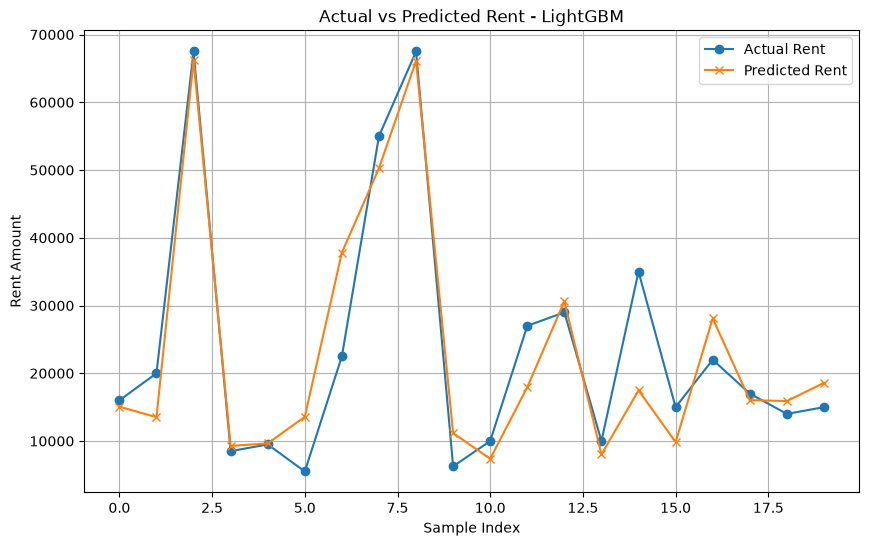

100%|██████████| 15/15 [01:02<00:00,  4.14s/it]


In [41]:

from scipy.sparse import issparse

errors = {}

for model_name, model in tqdm(models.items()):

    # Convert sparse data to dense only for HistGradientBoosting
    if model_name == "HistGradientBoosting":
        X_train_model = X_train.toarray() if issparse(X_train) else X_train
        X_test_model = X_test.toarray() if issparse(X_test) else X_test
    else:
        X_train_model = X_train
        X_test_model = X_test

    # Training
    model.fit(X_train_model, y_train)

    # Evaluation
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(
        model, X_train_model, y_train
    )

    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(
        model, X_test_model, y_test
    )

    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R_Train,
        "R2 Test": R_Test
    }

    # Actual vs Predicted
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test_model[:20])

    plt.figure(figsize=(10, 6))
    plt.plot(range(20), y_test_plot, label="Actual Rent", marker="o")
    plt.plot(range(20), y_pred_plot, label="Predicted Rent", marker="x")

    plt.xlabel("Sample Index")
    plt.ylabel("Rent Amount")
    plt.title(f"Actual vs Predicted Rent - {model_name}")
    plt.legend()
    plt.grid()
    plt.show()


In [42]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [43]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [44]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

<Axes: >

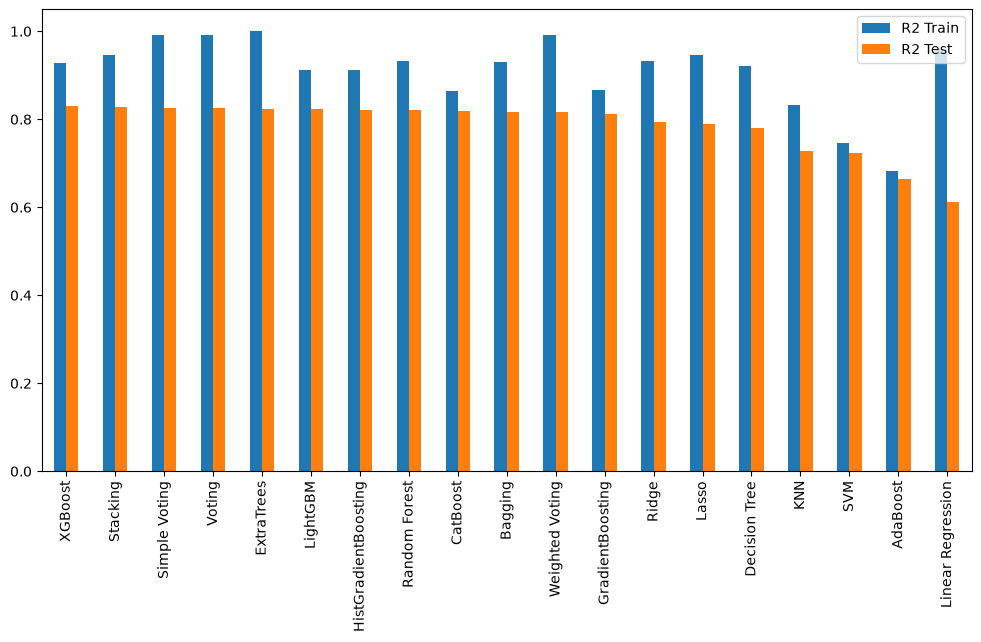

In [45]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

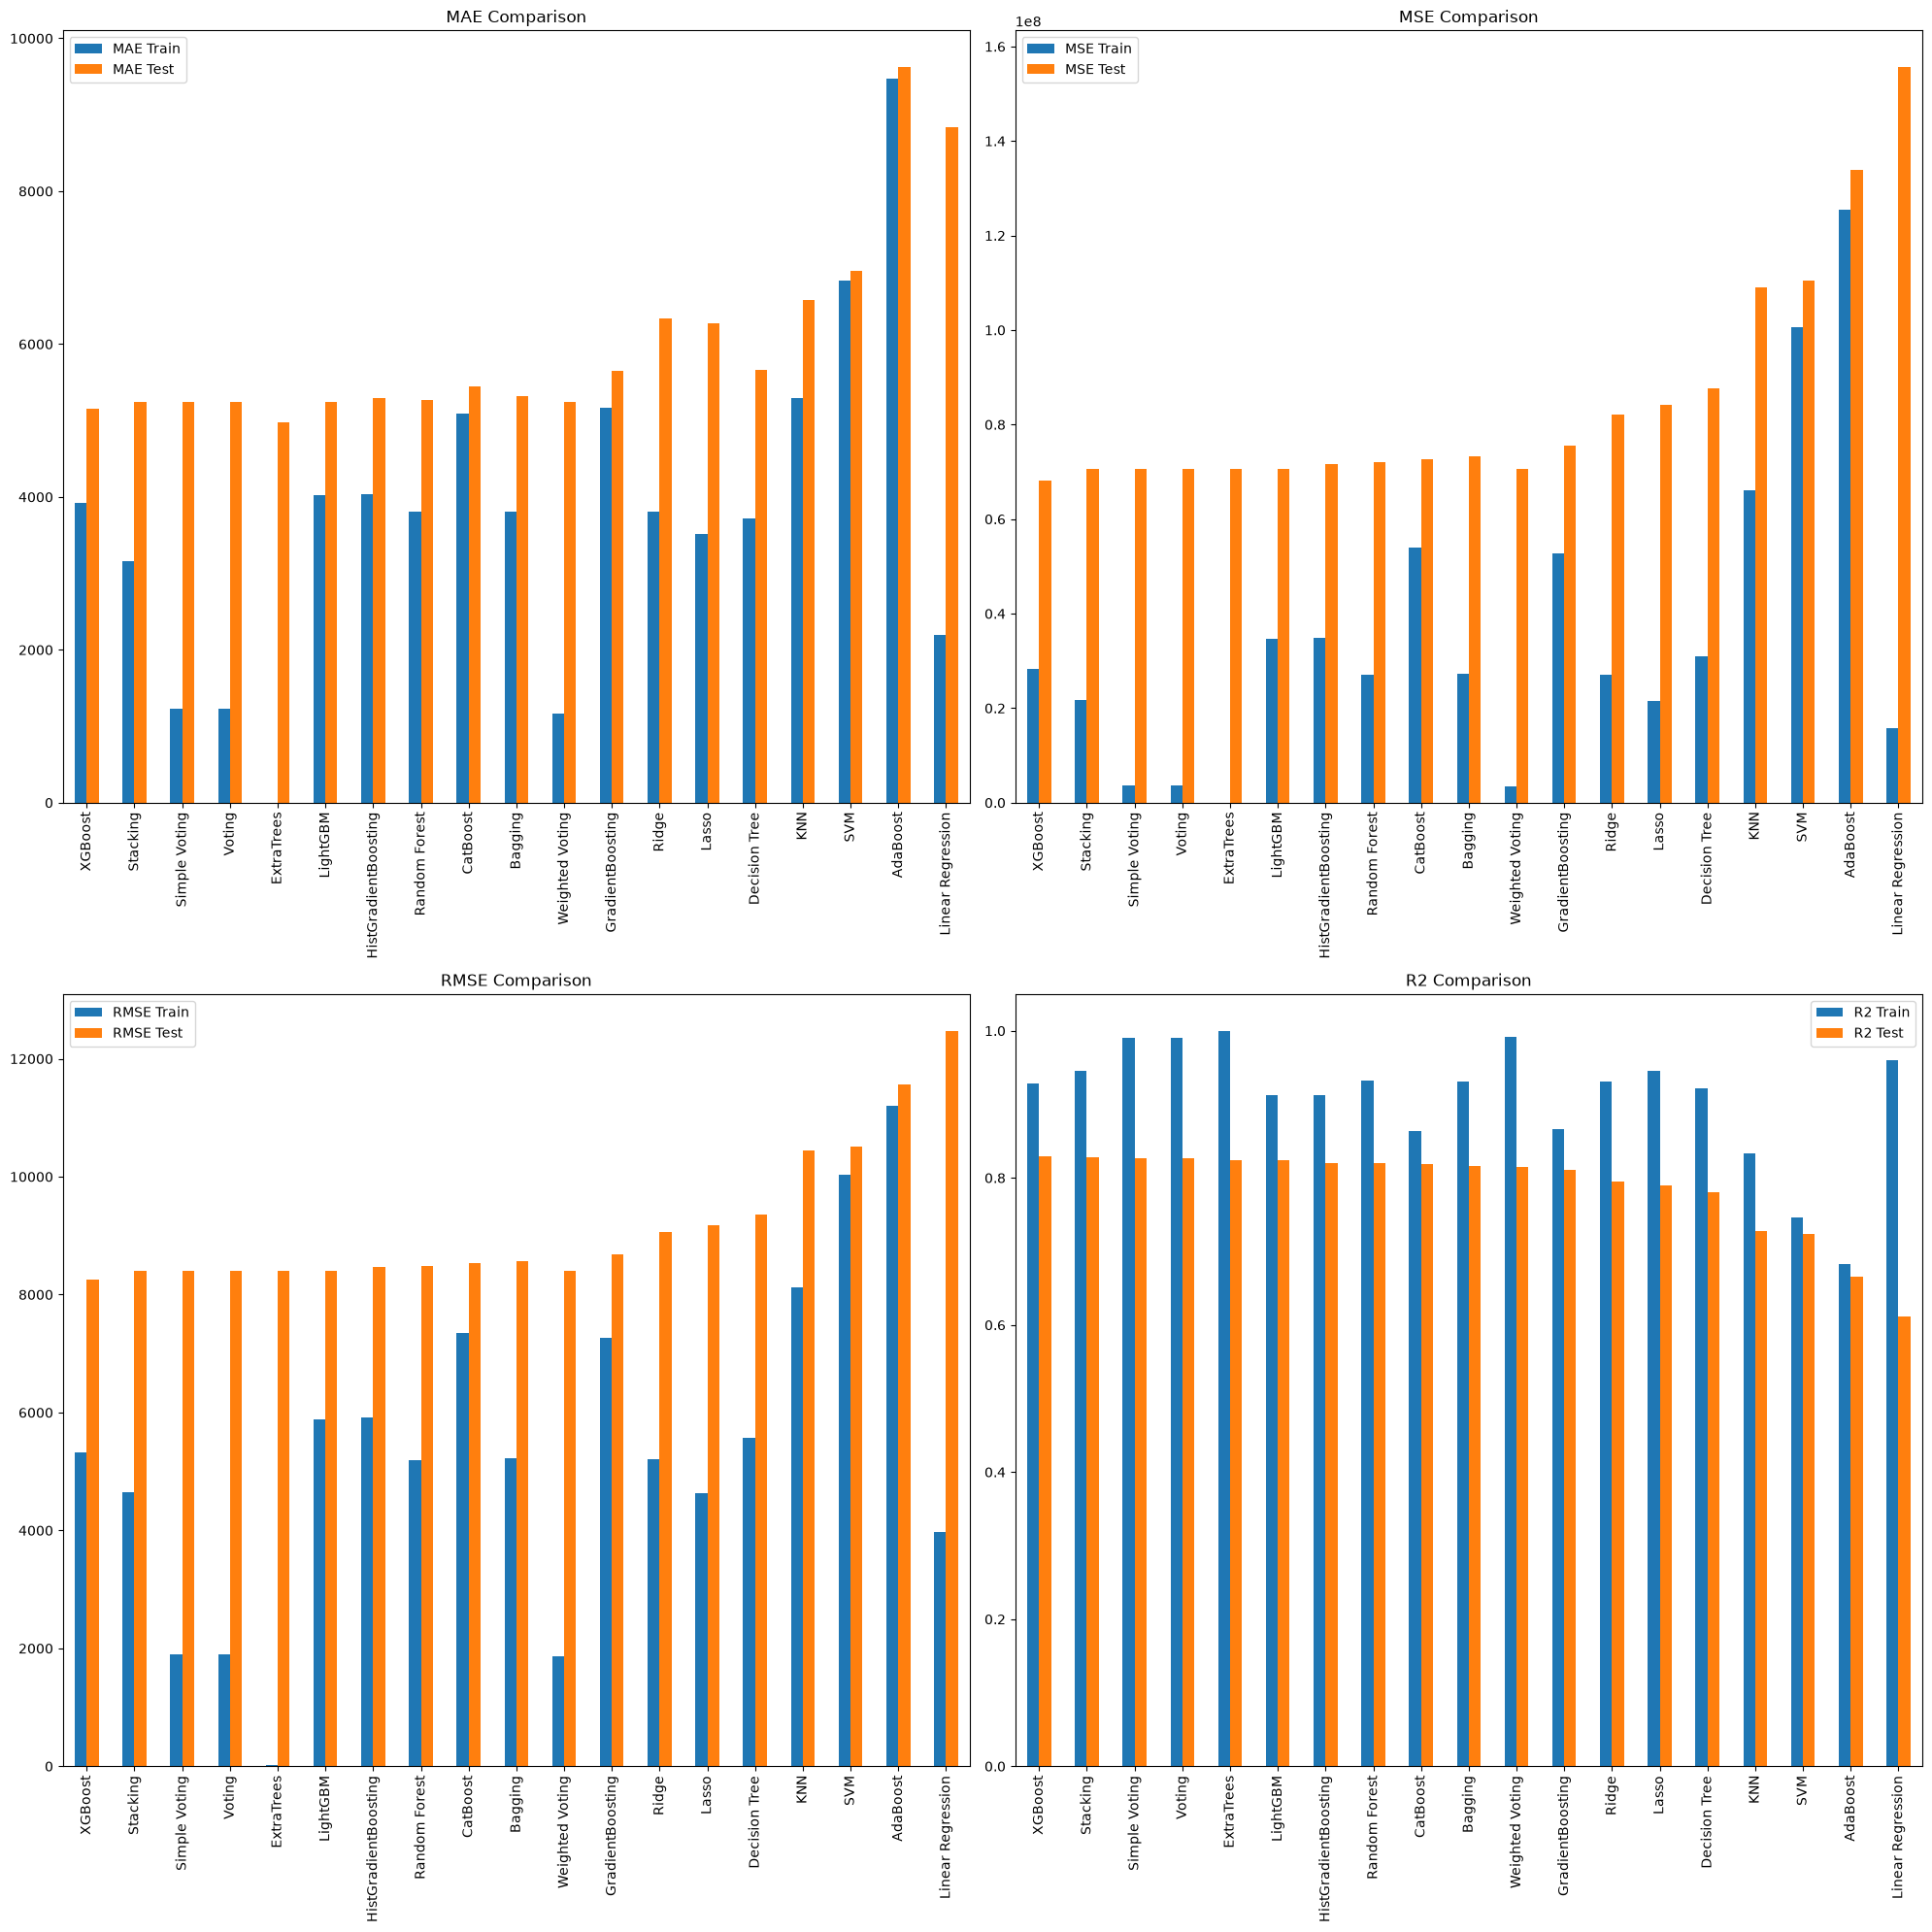

In [46]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)   
    errors_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [47]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
XGBoost,3927.822327,5150.730583,2.831240e+07,6.808607e+07,5320.939402,8251.428286,0.928551,0.829803
Stacking,3156.336484,5239.497611,2.166297e+07,7.064689e+07,4654.349485,8405.170598,0.945332,0.828621
Simple Voting,1225.710496,5239.497611,3.603657e+06,7.064689e+07,1898.330038,8405.170598,0.990906,0.826038
Voting,1225.710496,5239.497611,3.603657e+06,7.064689e+07,1898.330038,8405.170598,0.990906,0.826038
ExtraTrees,0.922996,4979.555796,4.285338e+02,7.063459e+07,20.701057,8404.438763,0.999999,0.823432
LightGBM,4020.100309,5239.497611,3.468057e+07,7.064689e+07,5889.021212,8405.170598,0.912481,0.823401
HistGradientBoosting,4035.140821,5290.158437,3.492010e+07,7.172490e+07,5909.323109,8469.055721,0.911876,0.820707
Random Forest,3803.562766,5274.475580,2.703511e+07,7.202479e+07,5199.529499,8486.742123,0.931775,0.819957
CatBoost,5087.082490,5447.473739,5.403392e+07,7.276031e+07,7350.776581,8529.965253,0.863641,0.818118
Bagging,3809.238145,5322.955087,2.730344e+07,7.331233e+07,5225.269036,8562.261878,0.931097,0.816738
